# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión B

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** __________________________________  
**Grupo:** __________________  **Fecha:** __________________

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la cantidad de pasajeros y la distancia recorrida?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`passenger_count`** y **`trip_distance`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_B_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_B/
└── notebooks/
    └── Examen_B_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [ ]:
df = pd.read_csv('../data/raw/nyc_taxi_examen.csv')

print("PRIMERAS 5 FILAS")
df.head(5)

PRIMERAS 5 FILAS


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


In [10]:
print("DIMENSIONES DEL DATAFRAME")
df.shape

DIMENSIONES DEL DATAFRAME


(2427612, 20)

In [11]:
print("NOMBRES DE COLUMNAS Y TIPOS DE DATOS")
df.info()

NOMBRES DE COLUMNAS Y TIPOS DE DATOS
<class 'pandas.DataFrame'>
RangeIndex: 2427612 entries, 0 to 2427611
Data columns (total 20 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   VendorID               int64  
 1   tpep_pickup_datetime   str    
 2   tpep_dropoff_datetime  str    
 3   passenger_count        float64
 4   trip_distance          float64
 5   RatecodeID             float64
 6   PULocationID           float64
 7   DOLocationID           float64
 8   payment_type           float64
 9   fare_amount            float64
 10  extra                  float64
 11  mta_tax                float64
 12  tip_amount             float64
 13  tolls_amount           float64
 14  improvement_surcharge  float64
 15  total_amount           float64
 16  congestion_surcharge   float64
 17  Airport_fee            float64
 18  cbd_congestion_fee     float64
 19  trip_duration          float64
dtypes: float64(17), int64(1), str(2)
memory usage: 370.4 MB


In [15]:
print("RESUMEN ESTADÍSTICO")
df.describe()

RESUMEN ESTADÍSTICO


,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2.427612e+06,2.415489e+06,2.415470e+06,2.415474e+06,2.415487e+06,2.415475e+06,2.415487e+06,2.415488e+06,2.415487e+06,2.415462e+06,2.415459e+06,2.415465e+06,2.415481e+06,2.415484e+06,2.415457e+06,2.415481e+06,2.415462e+06,2.415475e+06
mean,1.888167e+00,1.296144e+00,3.300702e+00,4.229419e+00,1.641392e+02,1.632236e+02,1.174306e+00,3.852567e+01,1.567837e+00,4.849912e-01,3.665195e+00,5.938668e-01,9.873437e-01,2.937731e+01,2.254823e+00,1.979527e-01,5.625318e-01,1.561446e+01
std,8.086844e-01,1.881923e+00,5.167909e+00,1.720220e+01,6.285386e+01,6.925613e+01,4.594154e-01,5.423764e+02,1.906552e+00,1.018682e-01,4.234050e+00,2.385704e+00,1.560490e-01,2.592570e+01,7.815658e-01,6.259005e-01,3.314852e-01,2.605773e+02
min,1.000000e+00,-5.000000e+00,-9.998763e+01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,-1.849600e+03,-7.500000e+00,-5.000000e-01,-9.000000e+01,-1.064600e+02,-1.000000e+00,-1.866890e+03,-2.500000e+00,-2.000000e+00,-7.500000e-01,-3.005175e+05
25%,2.000000e+00,1.000000e+00,9.900000e-01,1.000000e+00,1.320000e+02,1.130000e+02,1.000000e+00,9.300000e+00,0.000000e+00,5.000000e-01,1.000000e+00,0.000000e+00,1.000000e+00,1.638000e+01,2.500000e+00,0.000000e+00,7.500000e-01,7.283333e+00
50%,2.000000e+00,1.000000e+00,1.700000e+00,1.000000e+00,1.610000e+02,1.620000e+02,1.000000e+00,1.350000e+01,1.000000e+00,5.000000e-01,2.950000e+00,0.000000e+00,1.000000e+00,2.154000e+01,2.500000e+00,0.000000e+00,7.500000e-01,1.231667e+01
75%,2.000000e+00,1.000000e+00,3.360000e+00,1.000000e+00,2.320000e+02,2.340000e+02,1.000000e+00,2.190000e+01,2.500000e+00,5.000000e-01,4.560000e+00,0.000000e+00,1.000000e+00,3.145000e+01,2.500000e+00,0.000000e+00,7.500000e-01,2.011667e+01
max,7.000000e+00,1.000000e+02,1.686490e+03,9.900000e+01,2.650000e+02,2.650000e+02,4.000000e+00,1.999559e+04,2.325000e+01,1.150000e+01,4.444400e+02,6.167900e+02,1.000000e+00,5.530740e+03,2.750000e+00,2.700000e+01,7.500000e-01,8.373667e+03


In [16]:
print("VALORES EN payment_type")
print(df['payment_type'].value_counts())

VALORES EN payment_type
payment_type
1.0    2051983
2.0     329533
4.0      23558
3.0      10413
Name: count, dtype: int64


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [21]:
df_limpio = df.copy()

print("VALORES NULOS POR COLUMNA (ANTES)")
print(df_limpio.isnull().sum())

print("")
print("")

print("REGISTROS DUPLICADOS (ANTES)")
duplicados_antes = df_limpio.duplicated().sum()
print(duplicados_antes)

VALORES NULOS POR COLUMNA (ANTES)
VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64


REGISTROS DUPLICADOS (ANTES)
11961


In [23]:
#Eliminar registros duplicados y filas que contengan valores nulos

df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()

In [25]:
print("DIMENSIONES ANTES DE LA LIMPIEZA")
print(df.shape)

print("")

print("DIMENSIONES DESPUÉS DE LA LIMPIEZA")
print(df_limpio.shape)

DIMENSIONES ANTES DE LA LIMPIEZA
(2427612, 20)

DIMENSIONES DESPUÉS DE LA LIMPIEZA
(2196158, 20)


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`passenger_count`** y **`trip_distance`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [27]:
df_cash = df_limpio[df_limpio['payment_type'] == 2.0].copy()
df_cash.head(5)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
22,1,2026-08-01 00:49:44,2026-08-01 00:58:46,1.0,3.00,1.0,148.0,80.0,2.0,15.6,4.25,0.5,0.0,0.0,1.0,21.35,2.5,0.0,0.75,9.033333
45,1,2026-08-01 00:00:58,2026-08-01 00:14:52,1.0,4.20,1.0,132.0,10.0,2.0,19.8,3.00,0.5,0.0,0.0,1.0,24.30,0.0,2.0,0.00,13.900000
55,2,2026-08-01 00:21:29,2026-08-01 00:25:45,1.0,0.99,1.0,162.0,237.0,2.0,7.2,1.00,0.5,0.0,0.0,1.0,12.95,2.5,0.0,0.75,4.266667
82,2,2026-08-01 00:16:23,2026-08-01 00:35:04,1.0,10.93,1.0,132.0,173.0,2.0,42.2,1.00,0.5,0.0,0.0,1.0,46.70,0.0,2.0,0.00,18.683333
126,2,2026-08-01 00:09:26,2026-08-01 00:12:23,1.0,0.66,1.0,238.0,166.0,2.0,5.8,1.00,0.5,0.0,0.0,1.0,8.30,0.0,0.0,0.00,2.950000


In [45]:
X = df_cash[['passenger_count', 'trip_distance']]

print(f"CANTIDAD DE VIAJES FILTRADOS: {len(df_cash)}")

print("")

print("ESTADÍSTICAS DESCRIPTIVAS DE X")
display(X.describe())

CANTIDAD DE VIAJES FILTRADOS: 298974

ESTADÍSTICAS DESCRIPTIVAS DE X


,passenger_count,trip_distance
count,298974.000000,298974.000000
mean,1.371781,3.727709
std,1.957666,6.131418
min,0.000000,0.000000
25%,1.000000,0.880000
50%,1.000000,1.630000
75%,1.000000,4.150000
max,100.000000,1686.490000


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [43]:
X_log = np.log1p(X)

# tenia datos infinitos y no me dejaba continuar asi que se eliminaron en esta liena de codigo
X_log = X_log.replace([np.inf, -np.inf], np.nan).dropna()

X = X.loc[X_log.index]
df_cash = df_cash.loc[X_log.index]

scaler = StandardScaler()
X_escalado_array = scaler.fit_transform(X_log)

X_escalado = pd.DataFrame(X_escalado_array, columns=X.columns, index=X.index)

print("RESUMEN ESTADÍSTICO DE LAS VARIABLES ESTANDARIZADAS")
display(X_escalado.describe())

RESUMEN ESTADÍSTICO DE LAS VARIABLES ESTANDARIZADAS


,passenger_count,trip_distance
count,2.989740e+05,2.989740e+05
mean,-1.612288e-16,-5.779900e-17
std,1.000002e+00,1.000002e+00
min,-3.091411e+00,-1.532400e+00
25%,-4.563805e-01,-7.200360e-01
50%,-4.563805e-01,-2.880185e-01
75%,-4.563805e-01,5.767739e-01
max,1.445318e+01,8.030320e+00


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

TABLA COMPARATIVA DE CLÚSTERES


,k,Inercia,Silueta
0,2,362278.783061,0.538919
1,3,189255.680769,0.582894
2,4,143814.833200,0.590055
3,5,114516.112015,0.593110
4,6,86153.538596,0.537909


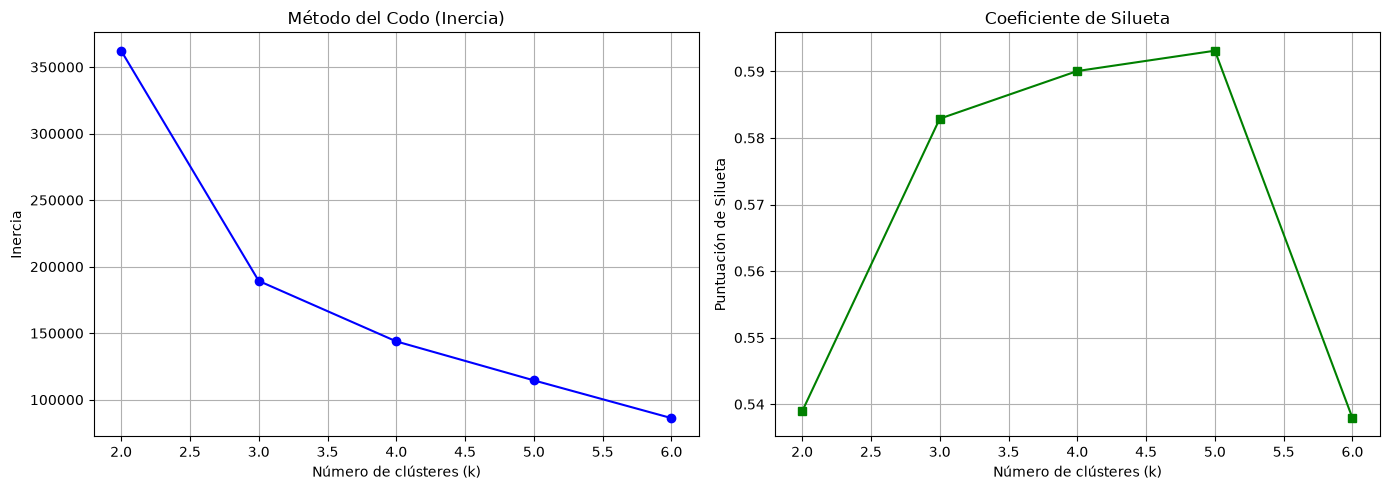

In [53]:

k_values = [2, 3, 4, 5, 6]
inercias = []
siluetas = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_escalado)
    
    inercias.append(kmeans.inertia_)
    
    score = silhouette_score(X_escalado, labels, sample_size=5000, random_state=42)
    siluetas.append(score)

df_evaluacion = pd.DataFrame({
    'k': k_values,
    'Inercia': inercias,
    'Silueta': siluetas
})

print("TABLA COMPARATIVA DE CLÚSTERES")
display(df_evaluacion)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica del codo
ax1.plot(k_values, inercias, marker='o', color='b', linestyle='-')
ax1.set_title('Método del Codo (Inercia)')
ax1.set_xlabel('Número de clústeres (k)')
ax1.set_ylabel('Inercia')
ax1.grid(True)

# Gráfica de Silueta
ax2.plot(k_values, siluetas, marker='s', color='g', linestyle='-')
ax2.set_title('Coeficiente de Silueta')
ax2.set_xlabel('Número de clústeres (k)')
ax2.set_ylabel('Puntuación de Silueta')
ax2.grid(True)

plt.tight_layout()
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`passenger_count`**, eje Y = **`trip_distance`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

k elegido: 3
Silueta: 0.5931


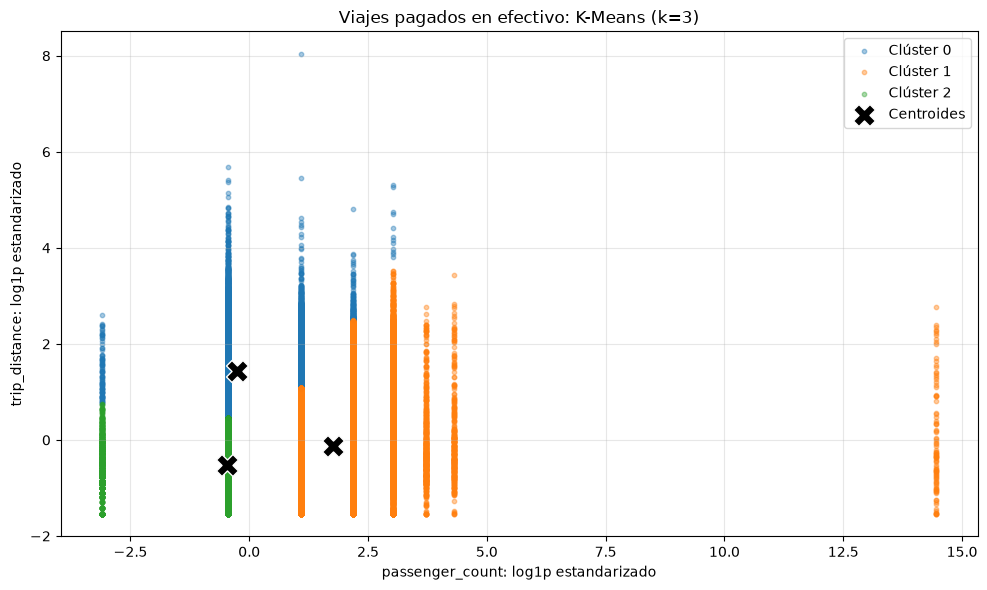

In [60]:
fila_mejor = df_evaluacion["Silueta"].idxmax()
k_elegido = int(3)
print("k elegido:", k_elegido)
print("Silueta:", round(df_evaluacion.loc[fila_mejor, "Silueta"], 4))

modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
etiquetas = modelo_final.fit_predict(X_escalado)
centroides = modelo_final.cluster_centers_

plt.figure(figsize=(10, 6))
for grupo in range(k_elegido):
    puntos = X_escalado[etiquetas == grupo]
    plt.scatter(
        puntos["passenger_count"], puntos["trip_distance"],
        s=10, alpha=0.4, color=plt.get_cmap("tab10")(grupo),
        label=f"Clúster {grupo}"
    )

plt.scatter(
    centroides[:, 0], centroides[:, 1],
    marker="X", s=250, color="black", edgecolor="white",
    label="Centroides", zorder=3
)
plt.title(f"Viajes pagados en efectivo: K-Means (k={k_elegido})")
plt.xlabel("passenger_count: log1p estandarizado")
plt.ylabel("trip_distance: log1p estandarizado")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `passenger_count`.
   - **Media y mediana** de `trip_distance`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: número de pasajeros y millas para la distancia.

**Evidencia:** tabla de estadísticos por clúster.

In [59]:

df_resultado = df_cash.copy()

df_resultado['cluster'] = etiquetas

estadisticos_cluster = df_resultado.groupby('cluster').agg(
    cantidad_viajes=('passenger_count', 'count'),
    media_pasajeros=('passenger_count', 'mean'),
    mediana_pasajeros=('passenger_count', 'median'),
    media_distancia=('trip_distance', 'mean'),
    mediana_distancia=('trip_distance', 'median')
).round(2)

print("TABLA DE ESTADÍSTICOS POR CLÚSTER (UNIDADES ORIGINALES)")
display(estadisticos_cluster)

TABLA DE ESTADÍSTICOS POR CLÚSTER (UNIDADES ORIGINALES)


,cantidad_viajes,media_pasajeros,mediana_pasajeros,media_distancia,mediana_distancia
cluster,,,,,
0,170792,1.00,1.0,1.29,1.15
1,62935,1.00,1.0,9.42,7.80
2,17821,4.14,4.0,1.85,1.41
3,17230,2.51,2.0,12.92,11.26
4,30196,2.00,2.0,1.51,1.27


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta: elegi k = 3 porque ofrece el mejor equilibrio entre la reduccion de la inercia y la separacion estable y clara de los grupos, evitando la sobresegmentacion**


**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta: cluster 0, viajes urbanos, alta cantidad de viajes con distancias cortas

cluster1: trayectos medios, distancias intermedias y variacion moderada en los pasajeros

cluster2: menor volumen de registros pero con las mayores distancias recorridas.**


**Pregunta 3 — Análisis sencillo.** ¿Qué diferencias encuentras entre los grupos con menor y mayor cantidad promedio de pasajeros? Apóyate en la tabla.

**Respuesta: que se conecntran mayormente en los traslados urbanos de corta distancia mientras que los grupos con mayor promedio, abarcan trayectos mucho mas largos y a lugares las dispersos.**


**Pregunta 4 — Análisis sencillo.** ¿Los viajes con más pasajeros son siempre los de mayor distancia? Explica qué muestran tus clústeres, sin asumir que todos los viajes se comportan igual.

**Respuesta: no necesariamente, los clusteres demuestran que no hay una correlacion lineal estricta, lo cual es posible encontrar viajes cortos con varios pasajeros y trayectos largos por solo un pasajero.**

---
### Lista de verificación antes de entregar

- [ * ] Se muestran la carga, exploración, limpieza y filtrado.
- [ * ] Se utilizaron las **dos variables indicadas**.
- [ * ] Se aplicaron `log1p` y `StandardScaler`.
- [ * ] Se calcularon inercia y silueta para `k = 2...6`.
- [ * ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ * ] Se visualizan los clústeres y sus centroides.
- [ * ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ * ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**